In [89]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

SEED = 42
np.random.seed(SEED)

đọc dữ liệu và chia train test

In [90]:
from pathlib import Path

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATHS = [
    BASE_DIR / "data" / "processed" / "gas_turbine_clean.csv",
    BASE_DIR / "data" / "raw" / "gas_turbine_data.csv",
]
DATA_PATH = next((path for path in DATA_PATHS if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy dữ liệu. Hãy đặt gas_turbine_data.csv vào data/raw/ "
        "hoặc gas_turbine_clean.csv vào data/processed/."
    )

df = pd.read_csv(DATA_PATH)
if "CO_clipped" not in df.columns:
    upper_limit = df["CO"].quantile(0.99)
    df["CO_clipped"] = df["CO"].clip(upper=upper_limit)

feature_cols = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
X = df[feature_cols]
y = df['CO_clipped']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print(f"Đã đọc dữ liệu từ: {DATA_PATH}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Đã đọc dữ liệu từ: d:\BTL---Machine-Learning---co3117-\data\processed\gas_turbine_clean.csv
Train: (29380, 9), Test: (7346, 9)


định nghĩa các model

In [91]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def scaled(m):
    return make_pipeline(StandardScaler(), m)


def unwrap_model(model):
    return model.steps[-1][1] if hasattr(model, "steps") else model


def build_model():
    return {
        "Naive (mean)": DummyRegressor(strategy="mean"),
        "Linear": scaled(LinearRegression()),
        "Ridge": scaled(RidgeCV(alphas=np.logspace(-3, 3, 13))),
        "Random Forest": RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED),
        "KNN": scaled(KNeighborsRegressor(n_neighbors=10, weights="distance", n_jobs=-1)),
        "MLP": scaled(MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                  max_iter=500, random_state=SEED)),
    }


def fit_eval(models, X_train, X_test, y_train, y_test):
    rows, preds = [], {}
    for name, model in models.items():
        t0 = time.time()
        model.fit(X_train, y_train)
        p_te, p_tr = model.predict(X_test), model.predict(X_train)
        preds[name] = p_te
        rows.append({
            "Model": name,
            "RMSE": np.sqrt(mean_squared_error(y_test, p_te)),
            "MAE": mean_absolute_error(y_test, p_te),

            "R2": r2_score(y_test, p_te),   

            "R2_train": r2_score(y_train, p_tr),
            "Times": time.time() - t0,
        })
    
    return pd.DataFrame(rows).set_index("Model"), preds

train và test

In [92]:
models=build_model()
result,preds=fit_eval(models,X_train,X_test,y_train,y_test)
result.sort_values("RMSE").round(4)

,RMSE,MAE,R2,R2_train,Times
Model,,,,,
Random Forest,0.7483,0.4403,0.8469,0.9788,6.4337
KNN,0.7685,0.4547,0.8385,1.0000,0.5585
MLP,0.7886,0.4916,0.8299,0.8441,7.6457
Linear,1.1017,0.7712,0.6681,0.6540,0.0217
Ridge,1.1017,0.7712,0.6681,0.6540,0.0413
Naive (mean),1.9125,1.3560,-0.0001,0.0000,0.0038


Model,RMSE,MAE,R2,R2_train,Times,Thông số chính
Random Forest,0.7483,0.4403,0.8469,0.9788,6.43 s,n_estimators=300; random_state=42
KNN,0.7685,0.4547,0.8385,1.0000,0.56 s,n_neighbors=10; weights=distance
MLP,0.7886,0.4916,0.8299,0.8441,7.65 s,"hidden_layer_sizes=(64, 32); early_stopping=True; max_iter=500"
Linear,1.1017,0.7712,0.6681,0.6540,0.02 s,fit_intercept=True
Ridge,1.1017,0.7712,0.6681,0.6540,0.04 s,"alphas=logspace(-3, 3, 13); alpha_chosen=0.1"
Naive (mean),1.9125,1.3560,-0.0001,0.0000,0.00 s,strategy=mean


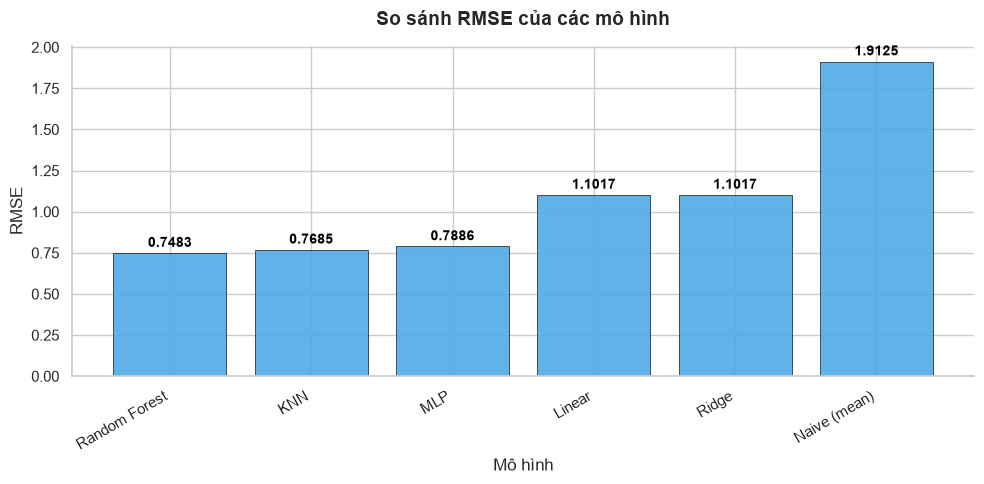

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns

ridge_est = unwrap_model(models["Ridge"])
linear_est = unwrap_model(models["Linear"])

model_configs = {
    "Naive (mean)": "strategy=mean",
    "Linear": f"fit_intercept={linear_est.fit_intercept}",
    "Ridge": f"alphas=logspace(-3, 3, 13); alpha_chosen={ridge_est.alpha_:.4g}",
    "Random Forest": "n_estimators=300; random_state=42",
    "KNN": "n_neighbors=10; weights=distance",
    "MLP": "hidden_layer_sizes=(64, 32); early_stopping=True; max_iter=500",
}

summary = result.sort_values("RMSE").copy()
summary["Thông số chính"] = summary.index.map(model_configs).fillna("-")

styled_summary = (
    summary.reset_index()
    .style
    .hide(axis="index")
    .format({
        "RMSE": "{:.4f}",
        "MAE": "{:.4f}",
        "R2": "{:.4f}",
        "R2_train": "{:.4f}",
        "Times": "{:.2f} s",
    })
    .background_gradient(subset=["RMSE"], cmap="RdYlGn_r", text_color_threshold=0)
    .set_caption("SO SÁNH HIỆU SUẤT CÁC MÔ HÌNH")
    .set_table_styles([
        {"selector": "caption", "props": [
            ("caption-side", "top"),
            ("text-align", "center"),
            ("font-size", "18px"),
            ("font-weight", "bold"),
            ("color", "black"),
            ("padding", "15px 0 15px 0"),
        ]},
        {"selector": "th", "props": [
            ("background-color", "#17324d"),
            ("color", "white"),
            ("text-align", "center"),
            ("font-size", "14px"),
            ("padding", "12px 15px"),
            ("border", "none"),
        ]},
        {"selector": "td", "props": [
            ("padding", "10px 15px"),
            ("border-bottom", "1px solid #d1d9e0"),
            ("text-align", "center"),
            ("vertical-align", "middle"),
            ("font-size", "13px"),
            ("color", "black"),
        ]},
        {"selector": "tbody tr:nth-child(odd) td", "props": [
            ("background-color", "#ffffff"),
        ]},
        {"selector": "tbody tr:nth-child(even) td", "props": [
            ("background-color", "#e6f2ff"),
        ]},
        {"selector": "tbody tr:hover td", "props": [
            ("background-color", "#cce5ff"),
        ]},
    ])
    .set_properties(subset=["Model"], **{"text-align": "left", "font-weight": "bold", "color": "black"})
)

display(styled_summary)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(summary.index, summary["RMSE"], color="#50aae6", edgecolor="black", linewidth=0.5, alpha=0.9)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.02, f"{yval:.4f}",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="black")

ax.set_title("So sánh RMSE của các mô hình", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Mô hình", fontsize=12)
ax.set_ylabel("RMSE", fontsize=12)
ax.tick_params(axis="x", labelrotation=30)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.tight_layout()
plt.show()

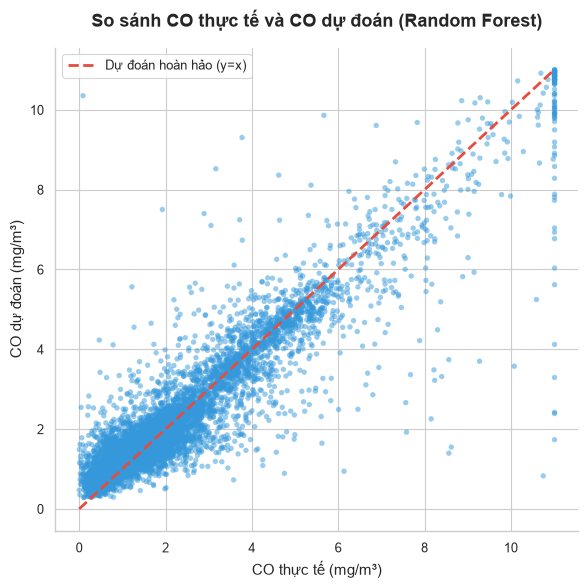

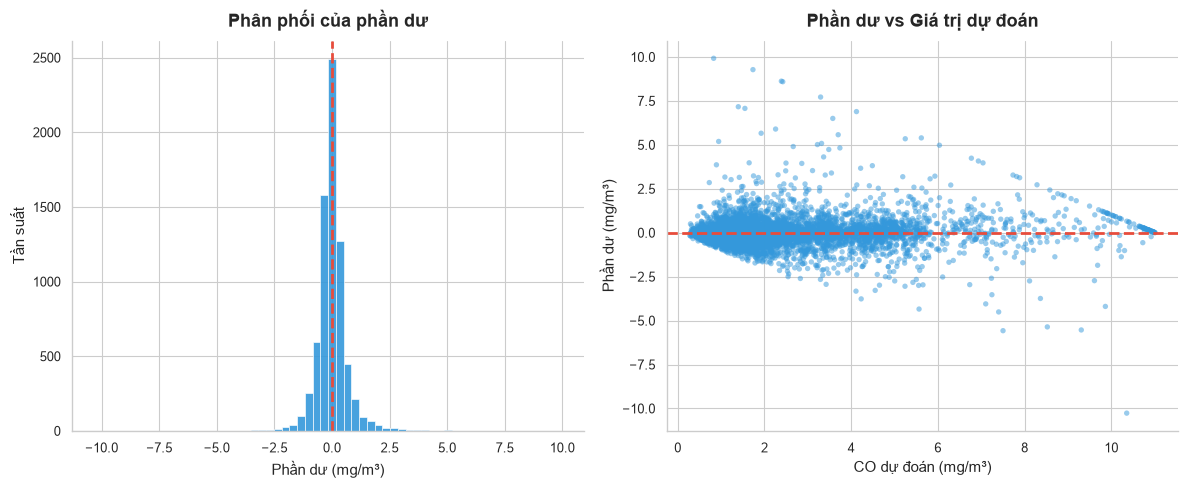

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cài đặt theme tổng thể cho đồ thị (thêm lưới mờ, nền trắng sáng)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

y_pred = preds["Random Forest"]
resid = y_test.to_numpy() - y_pred

# Định nghĩa màu sắc chủ đạo để dễ thay đổi
scatter_color = "#3498db" # Xanh dương nhạt cho các điểm dữ liệu
line_color = "#e74c3c"    # Đỏ cam cho đường line chuẩn
point_size = 15           # Tăng kích thước điểm lên một chút so với s=4
alpha_val = 0.5           # Độ trong suốt vừa phải để thấy rõ vùng dữ liệu dày đặc

# ==========================================
# HÌNH 4.2: BIỂU ĐỒ THỰC TẾ VS DỰ ĐOÁN
# ==========================================
fig, ax = plt.subplots(figsize=(6, 6)) # Tăng lên 6x6 để khung hình vuông vắn hơn

# Biểu đồ phân tán
ax.scatter(y_test, y_pred, s=point_size, alpha=alpha_val, color=scatter_color, edgecolor="none")

# Đường y=x (Đường dự đoán hoàn hảo)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, color=line_color, linestyle="--", linewidth=2, label="Dự đoán hoàn hảo (y=x)")

# Thêm tiêu đề và nhãn
ax.set_title("So sánh CO thực tế và CO dự đoán (Random Forest)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("CO thực tế (mg/m³)", fontsize=11)
ax.set_ylabel("CO dự đoán (mg/m³)", fontsize=11)

# Xóa viền trên và phải cho thoáng, thêm chú thích
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=True, loc='upper left')

plt.tight_layout()
fig.savefig("hinh_4_2.png", dpi=300, bbox_inches="tight") # Tăng DPI lên 300 để ảnh nét hơn khi cho vào báo cáo
plt.show()

# ==========================================
# HÌNH 4.3: PHÂN TÍCH PHẦN DƯ (RESIDUALS)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5)) # Tăng chiều ngang (12, 5) để 2 hình không bị ép dẹp

# Đồ thị 1: Histogram của phần dư
# Thêm edgecolor='white' để phân tách rõ các cột trong histogram
axes[0].hist(resid, bins=60, color=scatter_color, edgecolor='white', linewidth=0.5, alpha=0.9)
axes[0].axvline(0, color=line_color, linestyle="--", linewidth=2)
axes[0].set_title("Phân phối của phần dư", fontsize=13, fontweight="bold", pad=10)
axes[0].set_xlabel("Phần dư (mg/m³)", fontsize=11)
axes[0].set_ylabel("Tần suất", fontsize=11)

# Đồ thị 2: Scatter plot phần dư vs giá trị dự đoán
axes[1].scatter(y_pred, resid, s=point_size, alpha=alpha_val, color=scatter_color, edgecolor="none")
axes[1].axhline(0, color=line_color, linestyle="--", linewidth=2)
axes[1].set_title("Phần dư vs Giá trị dự đoán", fontsize=13, fontweight="bold", pad=10)
axes[1].set_xlabel("CO dự đoán (mg/m³)", fontsize=11)
axes[1].set_ylabel("Phần dư (mg/m³)", fontsize=11)

# Xóa viền trên và phải cho cả 2 đồ thị con
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
fig.savefig("hinh_4_3.png", dpi=300, bbox_inches="tight")
plt.show()

đa cộng tuyến : VIF và hệ số linear và ridge

VIF cao nên linear bth bị đa cộng tuyến cần dùng ridge

α trên dữ liệu chuẩn hoá: 0.1
Số biến đầu vào: 9
Danh sách biến: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']


,Biến,Linear,Ridge,SD boot Linear,SD boot Ridge,% đổi dấu Linear
0,AT,-0.3826,-0.3821,0.0193,0.0193,0.0
1,AP,-0.0208,-0.0207,0.0080,0.0080,0.5
2,AH,-0.1040,-0.1040,0.0081,0.0081,0.0
3,AFDP,-0.1265,-0.1265,0.0094,0.0094,0.0
4,GTEP,0.4892,0.4891,0.0388,0.0388,0.0
5,TIT,-1.0567,-1.0569,0.0375,0.0374,0.0
6,TAT,-0.4220,-0.4223,0.0236,0.0236,0.0
7,TEY,-2.7268,-2.7233,0.1067,0.1065,0.0
8,CDP,1.7564,1.7531,0.1079,0.1077,0.0


TEY     256.21
CDP     251.13
TIT      38.47
GTEP     29.86
TAT      10.25
AT        8.29
AFDP      2.49
AH        1.55
AP        1.52
Name: VIF, dtype: float64 

Ridge alpha được chọn:  0.1
      Linear   Ridge
AT   -0.3826 -0.3821
AP   -0.0208 -0.0207
AH   -0.1040 -0.1040
AFDP -0.1265 -0.1265
GTEP  0.4892  0.4891
TIT  -1.0567 -1.0569
TAT  -0.4220 -0.4223
TEY  -2.7268 -2.7233
CDP   1.7564  1.7531


,Biến,VIF,Mức,Tương quan mạnh nhất với,|r|
TEY,TEY,256.209,>10,CDP,0.989
CDP,CDP,251.129,>10,TEY,0.989
TIT,TIT,38.467,>10,TEY,0.910
GTEP,GTEP,29.862,>10,CDP,0.978
TAT,TAT,10.255,>10,CDP,0.705
AT,AT,8.291,5–10,AH,0.474
AFDP,AFDP,2.492,<5,CDP,0.702
AH,AH,1.552,<5,AT,0.474
AP,AP,1.520,<5,AT,0.409


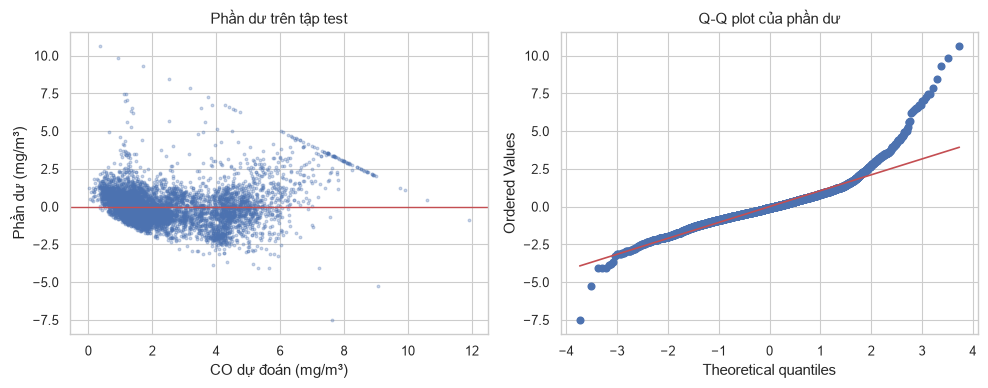

In [102]:
from sklearn.linear_model import LinearRegression, Ridge
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV

# Lấy estimator thật từ pipeline để đo coefficient/alpha
lin_est = unwrap_model(models["Linear"])
ridge_est = unwrap_model(models["Ridge"])

Xs = pd.DataFrame(StandardScaler().fit_transform(X_train), columns=X_train.columns)
ytr = np.asarray(y_train, float).ravel()
rcv = RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(Xs, ytr)
ALPHA_S = float(rcv.alpha_)
print("α trên dữ liệu chuẩn hoá:", ALPHA_S)

lin_s = LinearRegression().fit(Xs, ytr)
rid_s = Ridge(alpha=ALPHA_S).fit(Xs, ytr)

rng = np.random.default_rng(42)
cl, cr = [], []
for _ in range(200):
    i = rng.integers(0, len(Xs), len(Xs))
    cl.append(LinearRegression().fit(Xs.iloc[i], ytr[i]).coef_)
    cr.append(Ridge(alpha=ALPHA_S).fit(Xs.iloc[i], ytr[i]).coef_)
cl, cr = np.array(cl), np.array(cr)

tab_47 = pd.DataFrame({
    "Linear": lin_s.coef_,
    "Ridge": rid_s.coef_,
    "SD boot Linear": cl.std(0),
    "SD boot Ridge": cr.std(0),
    "% đổi dấu Linear": 100 * (np.sign(cl) != np.sign(lin_s.coef_)).mean(0),
}, index=Xs.columns)

tab_47 = tab_47.reset_index().rename(columns={"index": "Biến"})
print(f"Số biến đầu vào: {len(X.columns)}")
print("Danh sách biến:", list(X.columns))

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 1000)
pd.set_option("display.expand_frame_repr", False)
display(tab_47.round(4))

vif = pd.Series(
    np.diag(np.linalg.inv(np.corrcoef(X_train.values, rowvar=False))),
    index=X.columns,
    name="VIF",
)
print(vif.sort_values(ascending=False).round(2), "\n")

coef = pd.DataFrame({
    "Linear": lin_est.coef_,
    "Ridge": ridge_est.coef_,
}, index=X.columns)
print("Ridge alpha được chọn: ", ridge_est.alpha_)
print(coef.round(4))

# --- Bảng 4.6: thêm cột mức VIF và biến tương quan mạnh nhất ---
"""corr = X_train.corr().abs().where(~np.eye(len(cols), dtype=bool), 0)
tab_vif = pd.DataFrame({
    "VIF": vif,
    "Mức": pd.cut(vif, [0, 5, 10, np.inf], labels=["<5", "5–10", ">10"]),
    "Tương quan mạnh nhất với": corr.idxmax(),
    "|r|": corr.max(),
}).sort_values("VIF", ascending=False)
print(tab_vif.round(3))
"""
tab_vif = pd.DataFrame({
    "Biến": X.columns,
    "VIF": vif.values,
    "Mức": pd.cut(vif, [0, 5, 10, np.inf], labels=["<5", "5–10", ">10"]),
    "Tương quan mạnh nhất với": corr.idxmax().values,
    "|r|": corr.max().values,
}).sort_values("VIF", ascending=False)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", 1000,
    "display.expand_frame_repr", False
):
    display(tab_vif.round(3))

# --- Hình 4.5: phần dư của Linear trên test ---
yt = np.asarray(y_test, float).ravel()
res = yt - preds["Linear"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].scatter(preds["Linear"], res, s=4, alpha=0.3)
ax[0].axhline(0, color="r", lw=1)
ax[0].set_xlabel("CO dự đoán (mg/m³)")
ax[0].set_ylabel("Phần dư (mg/m³)")
ax[0].set_title("Phần dư trên tập test")

stats.probplot(res, dist="norm", plot=ax[1])
ax[1].set_title("Q-Q plot của phần dư")

fig.tight_layout()
fig.savefig("hinh_4_5.png", dpi=200, bbox_inches="tight")
plt.show()

Permutation importance ( random forest trên tập test)
đối chiếu với cơ sở vật lí : TIT cao thì CO giảm (đốt cháy hoàn toàn hơn)

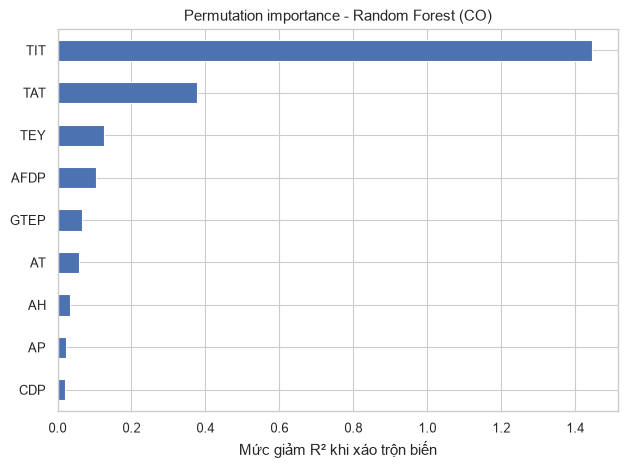

In [96]:
pi = permutation_importance(
    models["Random Forest"],
    X_test,
    y_test,
    n_repeats=3,
    random_state=SEED,
    n_jobs=1,
)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp.plot.barh(title="Permutation importance - Random Forest (CO)")
plt.xlabel("Mức giảm R² khi xáo trộn biến")
plt.tight_layout()
plt.show()

chia theo thời gian (train 80% đầu, test 20% cuối)

In [97]:
split =int(len(df)*0.8)
Xc_tr, Xc_te=X.iloc[:split],X.iloc[split:]
yc_tr,yc_te = y.iloc[:split],y.iloc[split:]
result_c,_=fit_eval(build_model(),Xc_tr,Xc_te,yc_tr,yc_te)
compare = result[["RMSE","R2"]].join(result_c[["RMSE","R2"]],
                                     lsuffix="_random",rsuffix="_time")
compare.sort_values("RMSE_time").round(4)

,RMSE_random,R2_random,RMSE_time,R2_time
Model,,,,
Random Forest,0.7483,0.8469,1.2979,0.5550
KNN,0.7685,0.8385,1.3590,0.5121
MLP,0.7886,0.8299,1.4690,0.4299
Linear,1.1017,0.6681,1.5262,0.3847
Ridge,1.1017,0.6681,1.5263,0.3846
Naive (mean),1.9125,-0.0001,2.1618,-0.2346


kiểm định wilcoxon trên sai số tuyệt đối

In [103]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

def compare_table(pairs, n_boot=1000, alpha=0.05, seed=42, save_path="bang_4_5.csv"):
    y = np.asarray(y_test, dtype=float).ravel()
    rng = np.random.default_rng(seed)
    n = len(y)
    idx = rng.integers(0, n, size=(n_boot, n))      # chỉ số bootstrap, dùng chung cho mọi cặp

    rows = []
    for a, b in pairs:
        ea = np.abs(y - preds[a])
        eb = np.abs(y - preds[b])
        d = ea - eb                                  # d < 0: A có sai số nhỏ hơn B

        try:
            p = wilcoxon(ea, eb).pvalue
        except ValueError:                           # mọi chênh lệch đều bằng 0
            p = 1.0

        boot = d[idx].mean(axis=1)                   # trung bình chênh lệch trên mỗi mẫu bootstrap
        lo, hi = np.percentile(boot, [2.5, 97.5])

        rows.append({
            "Cặp": f"{a} vs {b}",
            "MAE A": ea.mean(),
            "MAE B": eb.mean(),
            "ΔMAE (A−B)": d.mean(),
            "Δ%": 100 * d.mean() / eb.mean(),
            "KTC 95% thấp": lo,
            "KTC 95% cao": hi,
            "p Wilcoxon": p,
            "A tốt hơn B (% mẫu)": 100 * (d < 0).mean(),
        })

    tab = pd.DataFrame(rows)
    tab["p hiệu chỉnh"] = np.minimum(1.0, tab["p Wilcoxon"] * len(pairs))   # Bonferroni

    def verdict(r):
        if r["p hiệu chỉnh"] >= alpha or (r["KTC 95% thấp"] <= 0 <= r["KTC 95% cao"]):
            return "không phân biệt được"
        a, b = r["Cặp"].split(" vs ")
        return f"{a} tốt hơn" if r["ΔMAE (A−B)"] < 0 else f"{b} tốt hơn"

    tab["Kết luận"] = tab.apply(verdict, axis=1)

    if save_path:
        tab.to_csv(save_path, index=False)

    show = tab.copy()
    for c in ["MAE A", "MAE B", "ΔMAE (A−B)", "KTC 95% thấp", "KTC 95% cao"]:
        show[c] = show[c].map(lambda v: f"{v:.4f}")
    show["Δ%"] = show["Δ%"].map(lambda v: f"{v:+.1f}%")
    show["A tốt hơn B (% mẫu)"] = show["A tốt hơn B (% mẫu)"].map(lambda v: f"{v:.1f}%")
    for c in ["p Wilcoxon", "p hiệu chỉnh"]:
        show[c] = show[c].map(lambda v: f"{v:.3g}")
    print(show.to_string(index=False))
    return tab


pairs = [
    ("Random Forest", "KNN"),
    ("Random Forest", "MLP"),
    ("Random Forest", "Ridge"),
    ("Linear", "Ridge"),
    ("Random Forest", "Naive (mean)"),
]
tab_45 = compare_table(pairs)

                          Cặp  MAE A  MAE B ΔMAE (A−B)     Δ% KTC 95% thấp KTC 95% cao p Wilcoxon A tốt hơn B (% mẫu) p hiệu chỉnh              Kết luận
         Random Forest vs KNN 0.4403 0.4547    -0.0144  -3.2%      -0.0224     -0.0067    0.00325               51.4%       0.0162 Random Forest tốt hơn
         Random Forest vs MLP 0.4403 0.4916    -0.0513 -10.4%      -0.0593     -0.0433   2.66e-64               58.7%     1.33e-63 Random Forest tốt hơn
       Random Forest vs Ridge 0.4403 0.7712    -0.3308 -42.9%      -0.3444     -0.3175          0               72.1%            0 Random Forest tốt hơn
              Linear vs Ridge 0.7712 0.7712     0.0000  +0.0%      -0.0000      0.0000      0.667               50.6%            1  không phân biệt được
Random Forest vs Naive (mean) 0.4403 1.3560    -0.9157 -67.5%      -0.9446     -0.8882          0               85.0%            0 Random Forest tốt hơn


In [99]:
def tune_and_save_log(model, param_space, X_train, y_train, model_name, search_type='grid', cv=5):
    """
    Hàm thực hiện tuning mô hình, in kết quả và lưu log cv_results_ ra file CSV.
    """
    print(f"Đang tuning mô hình: {model_name}...")
    
    # 1. Cấu hình bộ tìm kiếm
    if search_type == 'grid':
        search = GridSearchCV(
            estimator=model,
            param_grid=param_space,
            cv=cv,
            scoring='neg_root_mean_squared_error', # Tiêu chí đánh giá là RMSE âm
            n_jobs=1,
            verbose=1
        )
    else:
        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_space,
            n_iter=20, # Số lượng tổ hợp ngẫu nhiên muốn thử
            cv=cv,
            scoring='neg_root_mean_squared_error',
            n_jobs=-1,
            random_state=42,
            verbose=1
        )
        
    # 2. Huấn luyện tìm siêu tham số
    search.fit(X_train, y_train)
    
    # 3. Trích xuất log cv_results_ và lưu thành file CSV
    cv_results_df = pd.DataFrame(search.cv_results_)
    csv_filename = f"cv_results_{model_name}.csv"
    cv_results_df.to_csv(csv_filename, index=False)
    
    print(f"--- KẾT QUẢ {model_name} ---")
    print(f"Tham số tốt nhất: {search.best_params_}")
    # Đổi dấu RMSE âm thành dương để dễ đọc
    print(f"RMSE tốt nhất (CV): {-search.best_score_:.4f}") 
    print(f"Đã lưu log toàn bộ quá trình thử nghiệm vào: {csv_filename}\n")
    
    # Trả về mô hình đã được gán sẵn tham số tốt nhất
    return search.best_estimator_

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

best_rf=tune_and_save_log(model=models["Random Forest"],param_space=rf_param_grid,X_train=X_train,y_train=y_train,model_name="RandomForest")

Đang tuning mô hình: RandomForest...
Fitting 5 folds for each of 27 candidates, totalling 135 fits
--- KẾT QUẢ RandomForest ---
Tham số tốt nhất: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}
RMSE tốt nhất (CV): 0.7683
Đã lưu log toàn bộ quá trình thử nghiệm vào: cv_results_RandomForest.csv

